In [17]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.patches import Patch
from IPython.display import HTML
from ipywidgets import interact, FloatSlider
from networkx.algorithms.community import louvain_communities
import warnings

warnings.filterwarnings('ignore')

# Configuración estética global estilo publicación científica
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = '#F4F6F9'
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['animation.embed_limit'] = 60.0

# Paleta cualitativa de alto contraste y armonía visual (Paul Tol's Muted Palette)
PALETA_HEX = [
    '#332288',  # 1. Índigo profundo
    '#CC6677',  # 2. Rosa coral
    '#44AA99',  # 3. Verde azulado (Teal)
    '#DDCC77',  # 4. Arena dorado
    '#882255',  # 5. Vino / Borgonha
    '#88CCEE',  # 6. Cian claro
    '#117733',  # 7. Verde bosque
    '#AA4499',  # 8. Púrpura
    '#999933'   # 9. Oliva
]

CMAP_COMUNIDADES = ListedColormap(PALETA_HEX * 5)

# Mapa de color continuo suave para las matrices de consenso D_{ij} en [0, 1]
CMAP_CONSENSO = LinearSegmentedColormap.from_list(
    'consenso_harm', ['#FFFFFF', '#88CCEE', '#44AA99', '#332288']
)

def map_colors(labels):
    """Devuelve la lista de colores hexadecimales para un vector de etiquetas."""
    return [PALETA_HEX[int(c) % len(PALETA_HEX)] for c in labels]

$$\mathcal{Q}^{M}=\frac{1}{\mu}\sum_{i,j;\alpha,\beta}\left\{\left(\mathcal{A}_{i\alpha,j\beta}-\gamma^{[\alpha]}\frac{k_{i}^{[\alpha]}k_{j}^{[\alpha]}}{\langle k^{[\alpha]}\rangle N}\right)\delta_{\alpha,\beta}+\omega\mathcal{A}_{i\alpha,j\beta}\delta_{ij}\right\}\delta(g_{i}^{[\alpha]},g_{j}^{[\beta]})$$


$\langle k^{[\alpha]}\rangle N = 2m^{[\alpha]} = \sum_{i,j} \mathcal{A}_{i\alpha, j\alpha}$ es el volumen de enlaces intracapa en la capa $\alpha$

$\gamma^{[\alpha]}$ es el parámetro de resolución de la capa $\alpha$

$\omega$ pondera los enlaces intercapa entre nodos réplica $(i, \alpha)$ e $(i, \beta)$.

In [18]:
def create_interesting_multilayer_network(N=32, seed=42):
    """
    Crea una red multicapa de 3 capas (N=32 nodos) con estructura mesoscópica diferenciada:
    - Capa 1 (Departamentos): 4 comunidades modulares bien definidas de 8 nodos.
    - Capa 2 (Proyectos Inter-grupo): Fusión parcial en 2 macro-bloques (C0+C1 y C2+C3).
    - Capa 3 (Social / Puentes): Nodos líderes (0, 8, 16, 24) actúan como hubs inter-comunitarios.
    Además devuelve un layout geométrico por clústeres para visualización limpia.
    """
    rng = np.random.default_rng(seed)
    B_size = N // 4  # 8 nodos por grupo base
    layers = []

    # Layout geométrico: 4 círculos locales dispuestos en los cuadrantes para evitar cruces caóticos
    pos = {}
    quadrant_centers = [(-2.2, 2.2), (2.2, 2.2), (-2.2, -2.2), (2.2, -2.2)]
    for b in range(4):
        cx, cy = quadrant_centers[b]
        angles = np.linspace(0, 2 * np.pi, B_size, endpoint=False)
        for k, node in enumerate(range(b * B_size, (b + 1) * B_size)):
            # El primer nodo de cada bloque (hub puente) se coloca ligeramente hacia el centro global
            radius = 0.65 if k == 0 else 1.15
            pos[node] = np.array([cx + radius * np.cos(angles[k] + np.pi/4),
                                  cy + radius * np.sin(angles[k] + np.pi/4)])

    layer_names = [
        "Capa 1: Micro-Comunidades (4 Grupos)",
        "Capa 2: Alianzas por Pares (2 Macro-Grupos)",
        "Capa 3: Red con Nodos Puente (Hubs)"
    ]

    for alpha in range(3):
        G = nx.Graph(name=layer_names[alpha])
        G.add_nodes_from(range(N))

        for i in range(N):
            for j in range(i + 1, N):
                bi, bj = i // B_size, j // B_size
                is_hub_i, is_hub_j = (i % B_size == 0), (j % B_size == 0)

                if alpha == 0:
                    # Capa 1: 4 bloques claros
                    p = 0.68 if bi == bj else 0.03
                elif alpha == 1:
                    # Capa 2: Bloques (0,1) unidos y (2,3) unidos
                    same_macro = (bi // 2 == bj // 2)
                    p = 0.60 if bi == bj else (0.28 if same_macro else 0.02)
                else:
                    # Capa 3: Fuerte conexión entre hubs puente y nodos frontera
                    if bi == bj:
                        p = 0.55
                    elif is_hub_i and is_hub_j:
                        p = 0.90  # Anillo denso entre líderes
                    elif is_hub_i or is_hub_j:
                        p = 0.18
                    else:
                        p = 0.02

                if rng.random() < p:
                    w = rng.uniform(0.7, 1.4)
                    G.add_edge(i, j, weight=round(w, 2))

        # Asegurar que cada capa sea conexa
        if not nx.is_connected(G):
            comps = [list(c) for c in nx.connected_components(G)]
            for idx in range(len(comps) - 1):
                G.add_edge(comps[idx][0], comps[idx + 1][0], weight=0.6)
        layers.append(G)

    return layers, pos


def build_multilayer_matrices(layers_G, omega=1.0, gamma=1.0, inter_mode='all-to-all'):
    """Construye la matriz de supra-modularidad B_{i\alpha, j\beta} (Ec. 8.2 de Bianconi)."""
    M = len(layers_G)
    N = layers_G[0].number_of_nodes()
    gamma_list = [float(gamma)] * M if isinstance(gamma, (int, float)) else list(gamma)

    total_nodes = N * M
    B = np.zeros((total_nodes, total_nodes), dtype=float)
    mu_intra, mu_inter = 0.0, 0.0

    for alpha in range(M):
        A_alpha = nx.to_numpy_array(layers_G[alpha], nodelist=range(N), weight='weight')
        k_alpha = A_alpha.sum(axis=1)
        deg_sum = k_alpha.sum()
        mu_intra += deg_sum
        P_alpha = np.outer(k_alpha, k_alpha) / deg_sum if deg_sum > 0 else np.zeros((N, N))
        B[alpha * N : (alpha + 1) * N, alpha * N : (alpha + 1) * N] = A_alpha - gamma_list[alpha] * P_alpha

    for alpha in range(M):
        for beta in range(M):
            if alpha != beta:
                if inter_mode == 'all-to-all' or (inter_mode == 'temporal' and abs(alpha - beta) == 1):
                    idx_a = np.arange(N) + alpha * N
                    idx_b = np.arange(N) + beta * N
                    B[idx_a, idx_b] = omega
                    mu_inter += omega * N

    return B, max(mu_intra + mu_inter, 1e-12), N, M


def compute_multilayer_modularity(B, mu, labels):
    """Evalúa Q^M = (1 / \mu) * \sum B_{u,v} \delta(g_u, g_v)."""
    same_comm = (labels[:, None] == labels[None, :]).astype(float)
    return float(np.sum(B * same_comm) / mu)


def canonical_relabel(labels_flat):
    """Ordena las etiquetas de 0 a P-1 por frecuencia y orden de aparición para colores consistentes."""
    vals, counts = np.unique(labels_flat, return_counts=True)
    order = vals[np.argsort(-counts)]
    mapping = {old: new for new, old in enumerate(order)}
    return np.array([mapping[v] for v in labels_flat], dtype=int)


def optimize_multilayer_modularity(layers_G, omega=1.0, gamma=1.0, inter_mode='all-to-all',
                                   max_sweeps=45, seed=42, record_history=False):
    """
    Optimiza Q^M mediante ascenso voraz Louvain sobre la supra-matriz y calcula
    la flexibilidad nodal f_i y global F (Ec. 8.5 de Bianconi).
    """
    rng = np.random.default_rng(seed)
    B, mu, N, M = build_multilayer_matrices(layers_G, omega=omega, gamma=gamma, inter_mode=inter_mode)
    total_nodes = N * M

    # Si grabamos historial para animación, iniciamos con 9 grupos aleatorios para visualizar la dinámica
    labels = rng.integers(0, 9, size=total_nodes) if record_history else np.arange(total_nodes)
    history = [canonical_relabel(labels).reshape(M, N)] if record_history else []

    B_sym = (B + B.T) / 2.0
    np.fill_diagonal(B_sym, 0.0)

    for sweep in range(max_sweeps):
        moves = 0
        for u in rng.permutation(total_nodes):
            curr_c = labels[u]
            unique_comms = np.unique(labels)
            gains = np.array([2.0 * np.sum(B_sym[u, labels == c]) for c in unique_comms])
            curr_idx = np.where(unique_comms == curr_c)[0][0]
            deltas = (gains - gains[curr_idx]) / mu

            best_idx = np.argmax(deltas)
            if deltas[best_idx] > 1e-9 and unique_comms[best_idx] != curr_c:
                labels[u] = unique_comms[best_idx]
                moves += 1
                if record_history and moves % 3 == 0:
                    history.append(canonical_relabel(labels).reshape(M, N))
        if moves == 0:
            break

    clean_labels = canonical_relabel(labels)
    partition_matrix = clean_labels.reshape(M, N)
    if record_history:
        history.append(partition_matrix.copy())

    Q_M = compute_multilayer_modularity(B, mu, clean_labels)
    f_i = np.sum(partition_matrix[1:, :] != partition_matrix[:-1, :], axis=0) / (M - 1) if M > 1 else np.zeros(N)

    return {
        'partition': partition_matrix,
        'Q_M': Q_M,
        'flexibility_node': f_i,
        'flexibility_mean': float(np.mean(f_i)),
        'history': history
    }

Se construye una red sintética de $M=3$ capas y $N=12$ nodos con bloques plantados que sufren pequeñas perturbaciones entre capas. Probamos los 5 regímenes solicitados para observar la persistencia intercapa ($\omega=0$ vs $\omega>0$) y el efecto de escala en el tamaño de las comunidades ($\gamma < 1$, $\gamma = 1$, $\gamma > 1$).

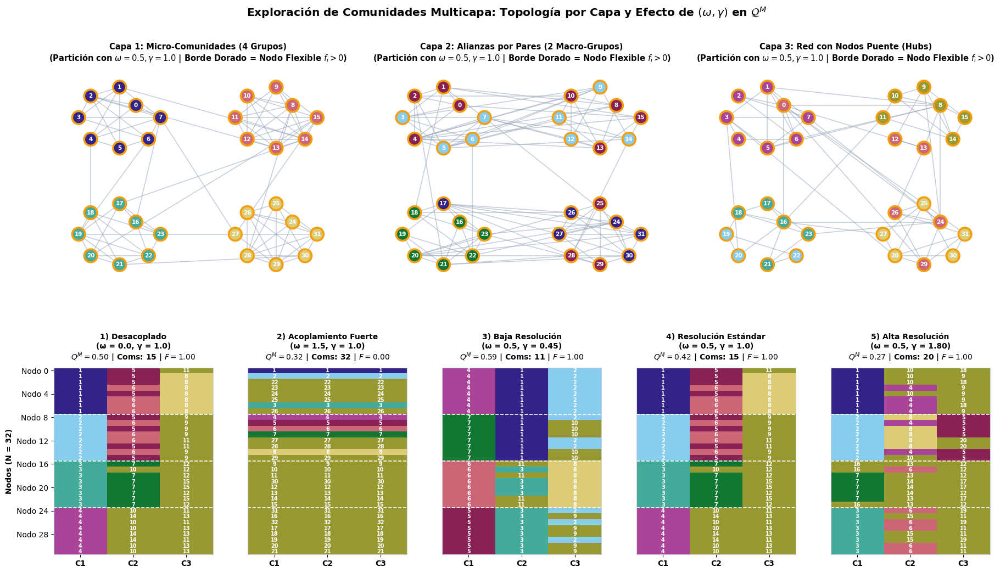

In [19]:
layers_net, pos_net = create_interesting_multilayer_network(N=32, seed=42)

scenarios = [
    ("1) Desacoplado\n(ω = 0.0, γ = 1.0)", 0.0, 1.0),
    ("2) Acoplamiento Fuerte\n(ω = 1.5, γ = 1.0)", 1.5, 1.0),
    ("3) Baja Resolución\n(ω = 0.5, γ = 0.45)", 0.5, 0.45),
    ("4) Resolución Estándar\n(ω = 0.5, γ = 1.0)", 0.5, 1.0),
    ("5) Alta Resolución\n(ω = 0.5, γ = 1.80)", 0.5, 1.80),
]

results_scen = [optimize_multilayer_modularity(layers_net, omega=w, gamma=g, seed=15) for _, w, g in scenarios]

fig = plt.figure(figsize=(22, 11.5))
gs = fig.add_gridspec(2, 6, height_ratios=[1.15, 1.0], hspace=0.42, wspace=0.28)

# --- FILA SUPERIOR: Visualización de la Red Multicapa (3 Capas) bajo Mesoescala Estándar (Escenario 4) ---
res_destacado = results_scen[3]  # omega=0.5, gamma=1.0
part_dest = res_destacado['partition']
flex_nodes = res_destacado['flexibility_node']

for alpha in range(3):
    ax_net = fig.add_subplot(gs[0, alpha * 2 : (alpha + 1) * 2])
    G_a = layers_net[alpha]
    cols = map_colors(part_dest[alpha])

    # Destacar con borde naranja/dorado grueso los nodos versátiles que cambian de comunidad entre capas (f_i > 0)
    edge_cols = ['#F59E0B' if flex_nodes[i] > 0 else '#1E293B' for i in range(32)]
    line_widths = [2.6 if flex_nodes[i] > 0 else 1.0 for i in range(32)]

    nx.draw_networkx_edges(G_a, pos_net, ax=ax_net, edge_color='#94A3B8', width=1.1, alpha=0.55)
    nx.draw_networkx_nodes(
        G_a, pos_net, ax=ax_net, node_color=cols,
        node_size=290, edgecolors=edge_cols, linewidths=line_widths
    )
    nx.draw_networkx_labels(G_a, pos_net, ax=ax_net, font_size=7.5, font_color='white', font_weight='bold')
    ax_net.set_title(f"{G_a.graph['name']}\n(Partición con $\\omega=0.5, \\gamma=1.0$ | Borde Dorado = Nodo Flexible $f_i > 0$)",
                     fontsize=10.5, fontweight='bold', pad=10)
    ax_net.axis('off')

# --- FILA INFERIOR: Los 5 Escenarios de Matrices de Afiliación (Nodos vs Capas) con Títulos Espaciados ---
gs_bottom = gs[1, :].subgridspec(1, 5, wspace=0.22)

for idx, ((title, w_val, g_val), res) in enumerate(zip(scenarios, results_scen)):
    ax_mat = fig.add_subplot(gs_bottom[0, idx])
    part = res['partition']  # (3, 32)
    n_comms = len(np.unique(part))

    ax_mat.imshow(part.T, aspect='auto', cmap=CMAP_COMUNIDADES, vmin=0, vmax=8, interpolation='nearest')
    ax_mat.set_title(
        f"{title}\n$Q^M={res['Q_M']:.2f}$ | Coms: {n_comms} | $F={res['flexibility_mean']:.2f}$",
        fontsize=10, fontweight='bold', pad=10
    )
    ax_mat.set_xticks(range(3))
    ax_mat.set_xticklabels(["C1", "C2", "C3"], fontweight='bold')

    for b_line in [7.5, 15.5, 23.5]:
        ax_mat.axhline(b_line, color='white', linestyle='--', linewidth=1.2)

    if idx == 0:
        ax_mat.set_yticks(range(0, 32, 4))
        ax_mat.set_yticklabels([f"Nodo {i}" for i in range(0, 32, 4)])
        ax_mat.set_ylabel("Nodos (N = 32)", fontweight='bold')
    else:
        ax_mat.set_yticks([])

    for r in range(32):
        for c in range(3):
            ax_mat.text(c, r, str(part[c, r] + 1), ha='center', va='center', color='white', fontsize=7, fontweight='bold')

fig.suptitle("Exploración de Comunidades Multicapa: Topología por Capa y Efecto de $(\\omega, \\gamma)$ en $\\mathcal{Q}^M$",
             fontsize=14.5, fontweight='bold', y=0.98)
plt.show()

# Algoritmo de Clustering por Consenso (Consensus Clustering)

In [20]:
def run_louvain_stochastic(G, n_p=30, gamma=1.0, weight_noise=0.12, base_seed=42):
    """
    Ejecuta Louvain n_p veces permutando el orden de visita de los nodos y añadiendo una
    perturbación estocástica suave a los pesos para muestrear múltiples óptimos locales.
    """
    rng = np.random.default_rng(base_seed)
    nodes = list(G.nodes())
    N = len(nodes)
    node_to_idx = {u: i for i, u in enumerate(nodes)}
    partitions = []

    for p in range(n_p):
        G_p = nx.Graph()
        G_p.add_nodes_from(rng.permutation(nodes))
        for u, v, d in G.edges(data=True):
            w = d.get('weight', 1.0)
            if weight_noise > 0:
                w = max(1e-4, w * rng.uniform(1.0 - weight_noise, 1.0 + weight_noise))
            G_p.add_edge(u, v, weight=w)

        comms = louvain_communities(G_p, weight='weight', resolution=gamma, seed=int(rng.integers(1, 1_000_000)))
        labels = np.zeros(N, dtype=int)
        for cid, comm in enumerate(comms):
            for u in comm:
                labels[node_to_idx[u]] = cid
        partitions.append(canonical_relabel(labels))

    return np.array(partitions)


def build_consensus_matrix(partitions):
    """Calcula la matriz de co-ocurrencia D_{ij} = n_{ij} / n_P (Ec. 8.6 de Bianconi)."""
    n_p, N = partitions.shape
    D = np.zeros((N, N), dtype=float)
    for p in range(n_p):
        D += (partitions[p][:, None] == partitions[p][None, :]).astype(float)
    D /= float(n_p)
    np.fill_diagonal(D, 0.0)
    return D


def threshold_consensus_matrix(D, tau, preserve_connectivity=True):
    """Poda las entradas D_{ij} < tau manteniendo la conectividad vía Maximum Spanning Tree si se solicita."""
    D_thresh = D.copy()
    D_thresh[D_thresh < tau] = 0.0

    if preserve_connectivity:
        G_orig = nx.from_numpy_array(D)
        G_thresh = nx.from_numpy_array(D_thresh)
        if nx.number_connected_components(G_thresh) > nx.number_connected_components(G_orig):
            mst = nx.maximum_spanning_tree(G_orig, weight='weight')
            for u, v, d in mst.edges(data=True):
                D_thresh[u, v] = D_thresh[v, u] = d['weight']
    return D_thresh


def check_partitions_equal(partitions):
    """Verifica convergencia exacta entre las n_P particiones (Paso vi)."""
    ref = (partitions[0][:, None] == partitions[0][None, :])
    return all(np.array_equal(ref, (partitions[p][:, None] == partitions[p][None, :])) for p in range(1, len(partitions)))


def consensus_clustering(G, n_p=30, tau=0.5, gamma=1.0, max_iter=15, preserve_connectivity=True, seed=42):
    """Algoritmo iterativo de Consensus Clustering (Lancichinetti & Fortunato 2012 / Bianconi Sec. 8.2.2)."""
    current_G = G.copy()
    history_D = []

    for it in range(max_iter):
        noise = 0.14 if it == 0 else 0.03
        partitions = run_louvain_stochastic(current_G, n_p=n_p, gamma=gamma, weight_noise=noise, base_seed=seed + it * 503)
        D = build_consensus_matrix(partitions)
        D_thresh = threshold_consensus_matrix(D, tau=tau, preserve_connectivity=preserve_connectivity)
        history_D.append((D.copy(), D_thresh.copy(), canonical_relabel(partitions[0])))

        if check_partitions_equal(partitions):
            break
        current_G = nx.from_numpy_array(D_thresh)

    return {
        'consensus_labels': history_D[-1][2],
        'D_raw_initial': history_D[0][0],
        'D_thresh_initial': history_D[0][1],
        'D_final': history_D[-1][0],
        'iterations': len(history_D),
        'history': history_D
    }

In [21]:
# Usamos la Capa 3 (Red con Nodos Puente y solapamiento, N=32) donde hay incertidumbre real en las fronteras
G_test = layers_net[2]
parts_init = run_louvain_stochastic(G_test, n_p=60, gamma=1.15, weight_noise=0.18, base_seed=77)
D_raw = build_consensus_matrix(parts_init)

def interact_consensus_threshold(tau=0.45):
    D_filt = threshold_consensus_matrix(D_raw, tau=tau, preserve_connectivity=False)
    G_cons = nx.from_numpy_array(D_filt)

    comms = louvain_communities(G_cons, weight='weight', resolution=1.0, seed=42)
    labels = np.zeros(G_test.number_of_nodes(), dtype=int)
    for cid, c in enumerate(comms):
        for u in c:
            labels[u] = cid
    labels = canonical_relabel(labels)
    node_cols = map_colors(labels)

    fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))

    # 1. Matriz de Consenso Original D_{ij}
    im0 = axes[0].imshow(D_raw, cmap=CMAP_CONSENSO, vmin=0, vmax=1)
    axes[0].set_title("1) Matriz de Consenso Empírica $D_{ij} = n_{ij}/n_P$\n($n_P = 60$ corridas estocásticas)", fontweight='bold')
    axes[0].set_xlabel("Nodo $j$")
    axes[0].set_ylabel("Nodo $i$")
    plt.colorbar(im0, ax=axes[0], fraction=0.046)

    # 2. Matriz Podada D_{ij} >= \tau
    im1 = axes[1].imshow(D_filt, cmap=CMAP_CONSENSO, vmin=0, vmax=1)
    n_edges_kept = G_cons.number_of_edges()
    axes[1].set_title(f"2) Matriz Filtrada por Umbral ($D_{{ij}} < \\tau = {tau:.2f} \\rightarrow 0$)\nAristas de consenso activas: {n_edges_kept}", fontweight='bold')
    axes[1].set_xlabel("Nodo $j$")
    plt.colorbar(im1, ax=axes[1], fraction=0.046)

    # 3. Grafo de Consenso Ponderado + Topología Original de Fondo
    ax2 = axes[2]
    # Dibujamos primero la red original en gris tenue como referencia estructural
    nx.draw_networkx_edges(G_test, pos_net, ax=ax2, edge_color='#CBD5E1', style='dashed', width=0.8, alpha=0.5)
    # Dibujamos encima las aristas de consenso D_{ij} >= tau con grosor proporcional a su peso
    cons_edges = G_cons.edges(data=True)
    cons_weights = [d['weight'] * 2.8 for _, _, d in cons_edges]
    nx.draw_networkx_edges(G_cons, pos_net, ax=ax2, width=cons_weights, edge_color='#332288', alpha=0.65)
    nx.draw_networkx_nodes(G_cons, pos_net, ax=ax2, node_color=node_cols, node_size=280, edgecolors='#1E293B', linewidths=1.2)
    nx.draw_networkx_labels(G_cons, pos_net, ax=ax2, font_size=7.5, font_color='white', font_weight='bold')
    ax2.set_title(f"3) Red de Consenso Ponderada\n({len(comms)} clústeres detectados)", fontweight='bold')
    ax2.axis('off')

    plt.tight_layout()
    plt.show()

interact(interact_consensus_threshold, tau=FloatSlider(min=0.05, max=0.95, step=0.05, value=0.45, description='Umbral τ:'));

interactive(children=(FloatSlider(value=0.45, description='Umbral τ:', max=0.95, min=0.05, step=0.05), Output(…

## Multicapa: Sliced Networks con Ventana Deslizante e Índice de Jaccard

$$J(C_a^{[w]}, C_b^{[w+1]}) = \frac{\vert{}C_a^{[w]} \cap C_b^{[w+1]}\vert{}}{\vert{}C_a^{[w]} \cup C_b^{[w+1]}\vert{}}$$

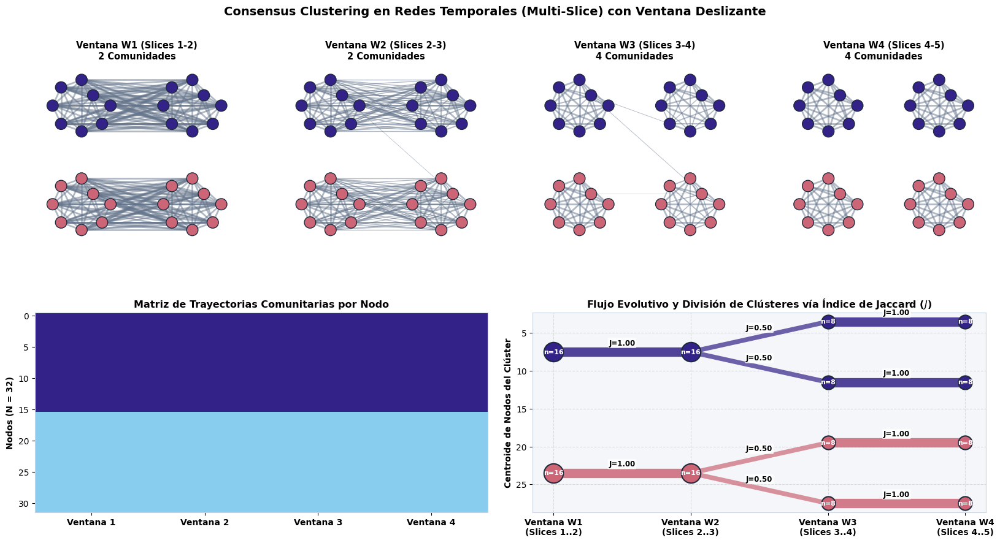

In [22]:
def jaccard_index(set_a, set_b):
    union = len(set_a.union(set_b))
    return len(set_a.intersection(set_b)) / union if union > 0 else 0.0

def sliced_consensus_clustering(temporal_slices, r=2, n_p=25, tau=0.45, gamma=1.0, jaccard_thresh=0.30, seed=42):
    M = len(temporal_slices)
    N = temporal_slices[0].number_of_nodes()
    num_windows = M - r + 1

    window_partitions, window_clusters_sets, window_graphs = [], [], []

    for w in range(num_windows):
        sub_slices = temporal_slices[w : w + r]
        all_parts = np.vstack([
            run_louvain_stochastic(G_s, n_p=n_p, gamma=gamma, weight_noise=0.10, base_seed=seed + w*300 + s*40)
            for s, G_s in enumerate(sub_slices)
        ])

        D_win = build_consensus_matrix(all_parts)
        D_win_thresh = threshold_consensus_matrix(D_win, tau=tau, preserve_connectivity=True)
        G_win_cons = nx.from_numpy_array(D_win_thresh)
        window_graphs.append(G_win_cons)

        res_win = consensus_clustering(G_win_cons, n_p=n_p, tau=tau, gamma=1.0, preserve_connectivity=True, seed=seed + w)
        labels_w = res_win['consensus_labels']
        window_partitions.append(labels_w)
        window_clusters_sets.append({int(cid): set(np.where(labels_w == cid)[0]) for cid in np.unique(labels_w)})

    temporal_links = []
    cid_map = {(0, int(cid)): int(cid) for cid in np.unique(window_partitions[0])}
    global_labels = [window_partitions[0].copy()]
    next_gid = len(cid_map)

    for w in range(num_windows - 1):
        for cid_b, nodes_b in window_clusters_sets[w + 1].items():
            best_j, best_cid_a = 0.0, None
            for cid_a, nodes_a in window_clusters_sets[w].items():
                j_val = jaccard_index(nodes_a, nodes_b)
                if j_val >= 0.12:
                    temporal_links.append((w, cid_a, w + 1, cid_b, j_val))
                if j_val > best_j:
                    best_j, best_cid_a = j_val, cid_a
            if best_j >= jaccard_thresh and best_cid_a is not None:
                cid_map[(w + 1, cid_b)] = cid_map[(w, best_cid_a)]
            else:
                cid_map[(w + 1, cid_b)] = next_gid
                next_gid += 1
        global_labels.append(np.array([cid_map[(w + 1, int(c))] for c in window_partitions[w + 1]]))

    return {
        'global_labels': np.array(global_labels),
        'temporal_links': temporal_links,
        'window_clusters': window_clusters_sets,
        'window_graphs': window_graphs,
        'cid_map': cid_map
    }

# Creamos una red temporal de M = 5 slices (N = 32 nodos) con evolución estructural:
# Slice 1 y 2: 2 macro-coaliciones (Capa 2) -> Slice 3: Transición puente (Capa 3) -> Slice 4 y 5: División en 4 especialidades (Capa 1)
slices_seq = [
    layers_net[1].copy(),
    layers_net[1].copy(),
    layers_net[2].copy(),
    layers_net[0].copy(),
    layers_net[0].copy()
]

res_temp = sliced_consensus_clustering(slices_seq, r=2, n_p=25, tau=0.45, gamma=1.0, jaccard_thresh=0.30)
n_wins = len(res_temp['window_graphs'])

fig = plt.figure(figsize=(20, 9.5))
gs_t = fig.add_gridspec(2, n_wins, height_ratios=[1.0, 1.1], hspace=0.35, wspace=0.22)

# Fila Superior: Redes de consenso en cada ventana deslizante
for w in range(n_wins):
    ax_w = fig.add_subplot(gs_t[0, w])
    G_w = res_temp['window_graphs'][w]
    cols_w = map_colors(res_temp['global_labels'][w])
    weights_w = [d['weight'] * 2.0 for _, _, d in G_w.edges(data=True)]

    nx.draw_networkx_edges(G_w, pos_net, ax=ax_w, width=weights_w, edge_color='#64748B', alpha=0.5)
    nx.draw_networkx_nodes(G_w, pos_net, ax=ax_w, node_color=cols_w, node_size=180, edgecolors='#1E293B')
    ax_w.set_title(f"Ventana W{w+1} (Slices {w+1}-{w+2})\n{len(res_temp['window_clusters'][w])} Comunidades", fontweight='bold', fontsize=10.5)
    ax_w.axis('off')

# Fila Inferior Izquierda: Matriz Temporal de Nodos vs Ventanas
ax_mat_t = fig.add_subplot(gs_t[1, :2])
ax_mat_t.imshow(res_temp['global_labels'].T, aspect='auto', cmap=CMAP_COMUNIDADES, vmin=0, vmax=8, interpolation='nearest')
ax_mat_t.set_title("Matriz de Trayectorias Comunitarias por Nodo", fontweight='bold', fontsize=11.5)
ax_mat_t.set_xticks(range(n_wins))
ax_mat_t.set_xticklabels([f"Ventana {w+1}" for w in range(n_wins)], fontweight='bold')
ax_mat_t.set_ylabel("Nodos (N = 32)", fontweight='bold')

# Fila Inferior Derecha: Diagrama de Bifurcación con Índice de Jaccard (Estilo Fig. 8.3 APS Network)
ax_jac = fig.add_subplot(gs_t[1, 2:])
ax_jac.set_title("Flujo Evolutivo y División de Clústeres vía Índice de Jaccard ($J$)", fontweight='bold', fontsize=11.5)

for (w, ca, w_next, cb, j_val) in res_temp['temporal_links']:
    ya = np.mean(list(res_temp['window_clusters'][w][ca]))
    yb = np.mean(list(res_temp['window_clusters'][w_next][cb]))
    col_link = PALETA_HEX[res_temp['cid_map'][(w, ca)] % len(PALETA_HEX)]
    ax_jac.plot([w, w_next], [ya, yb], color=col_link, alpha=min(0.85, j_val + 0.2), linewidth=j_val * 11, zorder=2)
    ax_jac.text((w + w_next)/2, (ya + yb)/2 - 0.9, f"J={j_val:.2f}", fontsize=8.5, ha='center', fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.15', facecolor='white', alpha=0.8, edgecolor='none'))

for w, clusters in enumerate(res_temp['window_clusters']):
    for cid, nodes_set in clusters.items():
        y_pos = np.mean(list(nodes_set))
        gid = res_temp['cid_map'][(w, cid)]
        ax_jac.scatter(w, y_pos, s=len(nodes_set) * 32, color=PALETA_HEX[gid % len(PALETA_HEX)], zorder=4, edgecolors='#1E293B', linewidths=1.5)
        ax_jac.text(w, y_pos, f"n={len(nodes_set)}", ha='center', va='center', color='white', fontsize=8, fontweight='bold', zorder=5)

ax_jac.set_xticks(range(n_wins))
ax_jac.set_xticklabels([f"Ventana W{w+1}\n(Slices {w+1}..{w+2})" for w in range(n_wins)], fontweight='bold')
ax_jac.set_ylabel("Centroide de Nodos del Clúster", fontweight='bold')
ax_jac.invert_yaxis()
ax_jac.grid(True, linestyle='--', alpha=0.4)
plt.suptitle("Consensus Clustering en Redes Temporales (Multi-Slice) con Ventana Deslizante", fontsize=14, fontweight='bold', y=0.98)
plt.show()

# Animaciones

## Algoritmo 1

In [24]:
res_anim1 = optimize_multilayer_modularity(layers_net, omega=0.55, gamma=1.0, seed=2026, record_history=True)
history_a1 = res_anim1['history']
B_a1, mu_a1, N_a1, M_a1 = build_multilayer_matrices(layers_net, omega=0.55, gamma=1.0)

# Pre-calculamos la curva de modularidad Q^M en cada paso registrado
q_trajectory = [compute_multilayer_modularity(B_a1, mu_a1, st.flatten()) for st in history_a1]

# Seleccionamos hasta 28 frames equiespaciados para fluidez óptima
n_total_a1 = len(history_a1)
frames_a1 = np.unique(np.linspace(0, n_total_a1 - 1, min(28, n_total_a1), dtype=int))

fig_a1 = plt.figure(figsize=(18, 8.2))
gs_a1 = fig_a1.add_gridspec(2, 3, height_ratios=[1.25, 0.85], hspace=0.35, wspace=0.22)
axes_top_a1 = [fig_a1.add_subplot(gs_a1[0, a]) for a in range(3)]
ax_curve_a1 = fig_a1.add_subplot(gs_a1[1, :2])
ax_mat_a1 = fig_a1.add_subplot(gs_a1[1, 2])
fig_a1.subplots_adjust(top=0.88, bottom=0.08)
plt.close(fig_a1)

def update_anim1(f_idx):
    step = frames_a1[f_idx]
    state = history_a1[step]
    q_val = q_trajectory[step]
    n_comms = len(np.unique(state))

    # 1. Actualizar las 3 redes en la fila superior
    for alpha in range(3):
        ax = axes_top_a1[alpha]
        ax.clear()
        G_a = layers_net[alpha]
        nx.draw_networkx_edges(G_a, pos_net, ax=ax, edge_color='#94A3B8', width=1.1, alpha=0.55)
        nx.draw_networkx_nodes(
            G_a, pos_net, ax=ax, node_color=map_colors(state[alpha]),
            node_size=240, edgecolors='#1E293B', linewidths=1.0
        )
        nx.draw_networkx_labels(G_a, pos_net, ax=ax, font_size=7, font_color='white', font_weight='bold')
        ax.set_title(G_a.graph['name'], fontsize=10.5, fontweight='bold')
        ax.axis('off')

    # 2. Actualizar curva de ascenso de Q^M en tiempo real
    ax_curve_a1.clear()
    ax_curve_a1.plot(range(step + 1), q_trajectory[:step + 1], color='#332288', linewidth=2.5, marker='o', markersize=4)
    ax_curve_a1.set_xlim(0, max(1, n_total_a1 - 1))
    ax_curve_a1.set_ylim(min(q_trajectory) - 0.03, max(q_trajectory) + 0.04)
    ax_curve_a1.set_title("Curva de Optimización Voraz de la Modularidad Generalizada $\\mathcal{Q}^M$", fontweight='bold', fontsize=10.5)
    ax_curve_a1.set_xlabel("Paso de Reasignación Nodal")
    ax_curve_a1.set_ylabel("$\\mathcal{Q}^M$")
    ax_curve_a1.grid(True, linestyle='--', alpha=0.4)

    # 3. Actualizar matriz de estados (Capas vs Nodos)
    ax_mat_a1.clear()
    ax_mat_a1.imshow(state, aspect='auto', cmap=CMAP_COMUNIDADES, vmin=0, vmax=8, interpolation='nearest')
    ax_mat_a1.set_title(f"Asignación Multicapa ({n_comms} Clústeres)", fontweight='bold', fontsize=10.5)
    ax_mat_a1.set_yticks(range(3))
    ax_mat_a1.set_yticklabels(["Capa 1", "Capa 2", "Capa 3"], fontweight='bold')
    ax_mat_a1.set_xlabel("Índice de Nodo (0 a 31)")

    fig_a1.suptitle(
        f"Dinámica de Optimización de Modularidad Multicapa | Paso {step + 1}/{n_total_a1} | "
        f"$\\mathcal{{Q}}^M = {q_val:.4f}$ | Comunidades Activas: {n_comms}",
        fontsize=13, fontweight='bold'
    )
    return axes_top_a1 + [ax_curve_a1, ax_mat_a1]

anim_1 = animation.FuncAnimation(fig_a1, update_anim1, frames=len(frames_a1), interval=340, blit=False)
HTML(anim_1.to_jshtml())

## Algoritmo 2

In [25]:
N_mux = 32
tau_mux = 0.48
frames_a2_data = []
accum_parts_layer = [[] for _ in range(3)]

# --- FASE 1: Acumulación estocástica de n_P = 12 particiones con exploración multiescala ---
for run in range(1, 13):
    D_layers_step = []
    # Variamos ligeramente la resolución y el ruido térmico para hacer visible la incertidumbre en nodos frontera
    gamma_explore = 0.75 + (run % 4) * 0.35
    noise_explore = max(0.08, 0.38 - run * 0.022)

    for alpha in range(3):
        p_sample = run_louvain_stochastic(
            layers_net[alpha], n_p=1, gamma=gamma_explore, weight_noise=noise_explore, base_seed=run * 313 + alpha * 41
        )[0]
        accum_parts_layer[alpha].append(p_sample)
        D_layers_step.append(build_consensus_matrix(np.array(accum_parts_layer[alpha])))

    # Matriz de consenso multiplex combinada de las 3 capas (Ref. [70] de Bianconi)
    D_mux_comb = np.mean(D_layers_step, axis=0)
    D_mux_cut = threshold_consensus_matrix(D_mux_comb, tau=tau_mux, preserve_connectivity=True)

    G_mux = nx.from_numpy_array(D_mux_cut)
    comms_m = louvain_communities(G_mux, weight='weight', resolution=1.0, seed=run * 19)
    lbls_m = np.zeros(N_mux, dtype=int)
    for cid, c in enumerate(comms_m):
        for u in c:
            lbls_m[u] = cid
    lbls_m = canonical_relabel(lbls_m)

    # Calculamos la entropía / incertidumbre media de la matriz (entradas fuera de 0 y 1)
    uncertainty = float(np.mean(4.0 * D_mux_comb * (1.0 - D_mux_comb)))

    frames_a2_data.append({
        'phase': f"Fase 1 (Muestreo Estocástico): Acumulando $n_P = {run}/12$ particiones",
        'D_layers': [d.copy() for d in D_layers_step],
        'labels': lbls_m.copy(),
        'n_comms': len(comms_m),
        'uncertainty': uncertainty
    })

# --- FASE 2: Poda iterativa por umbral \tau y convergencia de bloques (Pasos iv a vi de Bianconi) ---
D_curr_layers = [d.copy() for d in frames_a2_data[-1]['D_layers']]
D_mux_global = np.mean(D_curr_layers, axis=0)

for it_ref in range(1, 9):
    new_D_layers = []
    tau_progressive = min(tau_mux + it_ref * 0.03, 0.70)

    for alpha in range(3):
        # Mezclamos gradualmente cada capa con el consenso multiplex y aplicamos el umbral \tau
        D_blend = 0.75 * D_curr_layers[alpha] + 0.25 * D_mux_global
        D_thr = threshold_consensus_matrix(D_blend, tau=tau_progressive, preserve_connectivity=True)
        G_thr = nx.from_numpy_array(D_thr)

        parts_it = run_louvain_stochastic(
            G_thr, n_p=12, gamma=1.0, weight_noise=max(0.0, 0.12 - it_ref * 0.02), base_seed=8000 + it_ref * 97 + alpha
        )
        new_D_layers.append(build_consensus_matrix(parts_it))

    D_curr_layers = new_D_layers
    D_mux_global = np.mean(D_curr_layers, axis=0)
    D_mux_cut = threshold_consensus_matrix(D_mux_global, tau=tau_mux, preserve_connectivity=True)

    G_mux = nx.from_numpy_array(D_mux_cut)
    comms_m = louvain_communities(G_mux, weight='weight', resolution=1.0, seed=42)
    lbls_m = np.zeros(N_mux, dtype=int)
    for cid, c in enumerate(comms_m):
        for u in c:
            lbls_m[u] = cid
    lbls_m = canonical_relabel(lbls_m)
    uncertainty = float(np.mean(4.0 * D_mux_global * (1.0 - D_mux_global)))

    frames_a2_data.append({
        'phase': f"Fase 2 (Poda $\\tau={tau_mux}$ y Re-Clustering): Iteración de Convergencia {it_ref}/8",
        'D_layers': [d.copy() for d in D_curr_layers],
        'labels': lbls_m.copy(),
        'n_comms': len(comms_m),
        'uncertainty': uncertainty
    })

fig_a2, axes_a2 = plt.subplots(2, 3, figsize=(18, 9.2))
fig_a2.subplots_adjust(top=0.86, bottom=0.06, hspace=0.34, wspace=0.22)
plt.close(fig_a2)

def update_anim2(idx):
    frame = frames_a2_data[idx]
    node_cols = map_colors(frame['labels'])

    for alpha in range(3):
        # Fila Superior: Red de Consenso de la Capa \alpha (aristas filtradas por D_{ij}^{[\alpha]} >= 0.35)
        ax_net = axes_a2[0, alpha]
        ax_net.clear()
        D_a = frame['D_layers'][alpha]
        D_vis = threshold_consensus_matrix(D_a, tau=0.35, preserve_connectivity=True)
        G_vis = nx.from_numpy_array(D_vis)

        # Aristas de la topología original al fondo en gris muy suave
        nx.draw_networkx_edges(layers_net[alpha], pos_net, ax=ax_net, edge_color='#E2E8F0', width=0.7, style='dotted')
        # Aristas del grafo de consenso cuyo grosor refleja D_{ij}
        w_edges = [d['weight'] * 2.5 for _, _, d in G_vis.edges(data=True)]
        nx.draw_networkx_edges(G_vis, pos_net, ax=ax_net, width=w_edges, edge_color='#332288', alpha=0.55)
        nx.draw_networkx_nodes(
            G_vis, pos_net, ax=ax_net, node_color=node_cols,
            node_size=230, edgecolors='#1E293B', linewidths=1.0
        )
        nx.draw_networkx_labels(G_vis, pos_net, ax=ax_net, font_size=6.5, font_color='white', font_weight='bold')
        ax_net.set_title(f"{layers_net[alpha].graph['name']}\n(Aristas activas $D_{{ij}} \\geq 0.35$: {G_vis.number_of_edges()})",
                         fontsize=10, fontweight='bold')
        ax_net.axis('off')

        # Fila Inferior: Matriz de Consenso D_{ij}^{[\alpha]} cristalizando en bloques diagonales
        ax_mat = axes_a2[1, alpha]
        ax_mat.clear()
        ax_mat.imshow(D_a, cmap=CMAP_CONSENSO, vmin=0.0, vmax=1.0, interpolation='nearest')
        ax_mat.set_title(f"Matriz de Consenso $D_{{ij}}^{{[{alpha+1}]}}$ (Densidad={np.mean(D_a > tau_mux):.2f})",
                         fontsize=10, fontweight='bold')
        ax_mat.set_xticks(range(0, N_mux, 8))
        ax_mat.set_yticks(range(0, N_mux, 8))
        ax_mat.set_xlabel("Nodo $j$")
        if alpha == 0:
            ax_mat.set_ylabel("Nodo $i$")

    fig_a2.suptitle(
        f"Consensus Clustering Multiplex en 3 Capas ($N={N_mux}$) | Cuadro {idx + 1}/{len(frames_a2_data)}\n"
        f"{frame['phase']} | Clústeres: {frame['n_comms']} | Incertidumbre de Frontera: {frame['uncertainty']:.3f}",
        fontsize=12.5, fontweight='bold'
    )
    return axes_a2.flatten()

anim_2 = animation.FuncAnimation(fig_a2, update_anim2, frames=len(frames_a2_data), interval=450, blit=False)
HTML(anim_2.to_jshtml())